In [ ]:
import math
import matplotlib.pyplot as plt
import numpy as np

from astro_tools.data.atmospheres import USSA1976
from astro_tools.data.bodies import KERBIN, MUN

from astro_tools.orbital_mechanics import orbital_period
from astro_tools.orbital_mechanics.transfers import hohmann_transfer, HohmannTransfer

In [4]:
alts = np.arange(1, 70_000, 1)

temperature = [KERBIN.atmosphere.molecular_scale_temperature(alt) for alt in alts]
pressure = [KERBIN.atmosphere.pressure(alt) for alt in alts]
density = [KERBIN.atmosphere.density(alt) for alt in alts]

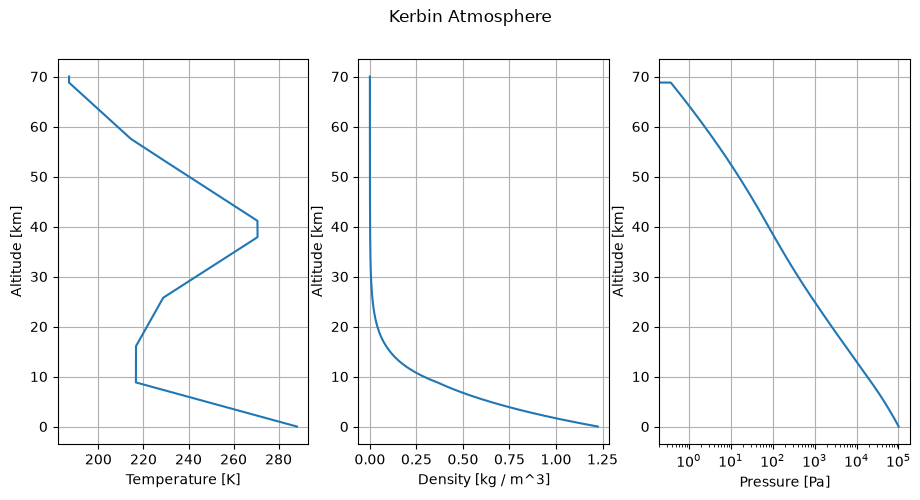

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(11, 5))
fig.suptitle("Kerbin Atmosphere")

axs[0].set_ylabel("Altitude [km]")
axs[0].set_xlabel("Temperature [K]")
axs[0].plot(temperature, alts / 1000)
axs[0].grid(True)

axs[1].set_ylabel("Altitude [km]")
axs[1].set_xlabel("Density [kg / m^3]")
axs[1].plot(density, alts / 1000)
axs[1].grid(True)

axs[2].set_ylabel("Altitude [km]")
axs[2].set_xlabel("Pressure [Pa]")
axs[2].set_xscale("log")
axs[2].plot(pressure, alts / 1000)
axs[2].grid(True)

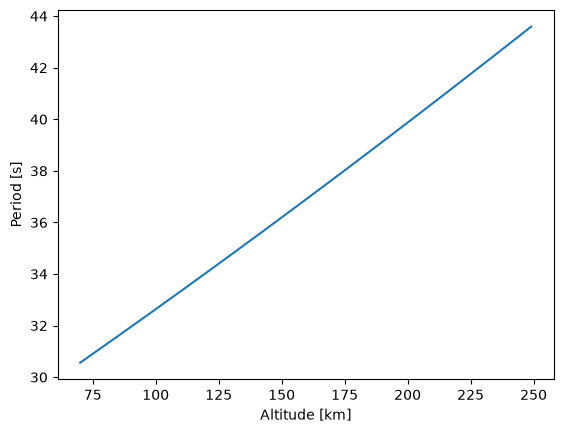

In [ ]:
alts = np.arange(70_000, 250_000, 1_000) + KERBIN.radius
periods = [orbital_period(KERBIN.mu, T)/60 for T in alts]


fig, ax = plt.subplots()

ax.set_xlabel('Altitude [km]')
ax.set_ylabel('Period [min]')
ax.plot((alts - KERBIN.radius) / 1000, periods)

In [ ]:
E_radius = 100_000
Mun_transfer_delta_v = hohmann_transfer(KERBIN.mu, E_radius, MUN.semi_major_axis)

print("Delta V for Earth to Mun transfer: ", Mun_transfer_delta_v)